In [1]:
# Step 1: Imports and configuration

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

SEED = 42

tf.keras.utils.set_random_seed(SEED)

PROJECT_ROOT = Path(
    r"C:\Users\Hey_Nerd\Desktop\plant-disease-classifier"
)

SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Project root:", PROJECT_ROOT)

I0000 00:00:1792247756.367446    2031 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project root: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier


In [2]:
# Step 2: Load the dataset manifests

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "validation.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Hey_Nerd\\Desktop\\plant-disease-classifier/data/splits/train.csv'

In [ ]:
# Step 3: Validate paths and class labels

assert train_df["file_path"].notna().all()
assert val_df["file_path"].notna().all()
assert test_df["file_path"].notna().all()

CLASS_NAMES = sorted(train_df["class_name"].unique())
NUM_CLASSES = len(CLASS_NAMES)

assert set(val_df["class_name"]) == set(CLASS_NAMES)
assert set(test_df["class_name"]) == set(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
print("Class names:")
print(CLASS_NAMES)

missing_files = [
    p
    for p in pd.concat(
        [
            train_df["file_path"],
            val_df["file_path"],
            test_df["file_path"]
        ]
    )
    if not Path(p).is_file()
]

print("Missing files:", len(missing_files))

assert not missing_files, (
    "Some image paths no longer exist. Check the raw dataset location."
)

Number of classes: 39
Class names:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Background_without_leaves', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot'

In [ ]:
# Step 4: Create a consistent class-to-index mapping

class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

train_df["label"] = (
    train_df["class_name"]
    .map(class_to_index)
    .astype("int32")
)

val_df["label"] = (
    val_df["class_name"]
    .map(class_to_index)
    .astype("int32")
)

test_df["label"] = (
    test_df["class_name"]
    .map(class_to_index)
    .astype("int32")
)

print("Example label mapping:")

for name in CLASS_NAMES[:10]:
    print(f"{name}: {class_to_index[name]}")

assert train_df["label"].between(0, NUM_CLASSES - 1).all()
assert val_df["label"].between(0, NUM_CLASSES - 1).all()
assert test_df["label"].between(0, NUM_CLASSES - 1).all()

Example label mapping:
Apple___Apple_scab: 0
Apple___Black_rot: 1
Apple___Cedar_apple_rust: 2
Apple___healthy: 3
Background_without_leaves: 4
Blueberry___healthy: 5
Cherry___Powdery_mildew: 6
Cherry___healthy: 7
Corn___Cercospora_leaf_spot Gray_leaf_spot: 8
Corn___Common_rust: 9


In [ ]:
# Save class labels for future inference

class_names_path = MODELS_DIR / "class_names.json"

with open(class_names_path, "w", encoding="utf-8") as file:
    json.dump(CLASS_NAMES, file, indent=2)

print("Class mapping saved to:", class_names_path)

Class mapping saved to: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\models\class_names.json


In [ ]:
# Step 5: Define image loading and preprocessing

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess_image(file_path, label):
    image_bytes = tf.io.read_file(file_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    # Set a known rank and channel count after decoding
    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE,
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    return image, label

In [ ]:
# Step 6: Build efficient tf.data datasets

def create_dataset(dataframe, training=False):
    paths = dataframe["file_path"].astype(str).to_numpy()
    labels = dataframe["label"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)

# Keep test_ds separate for final evaluation
test_ds = create_dataset(test_df, training=False)

print("Dataset pipelines created successfully.")

Dataset pipelines created successfully.


In [ ]:
# Step 7: Inspect a batch

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Pixel value range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

print("First label:", int(labels[0].numpy()))
print("First class:", CLASS_NAMES[int(labels[0].numpy())])

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Image tensor dtype: <dtype: 'float32'>
Pixel value range: 0.0 to 247.9375
First label: 5
First class: Blueberry___healthy


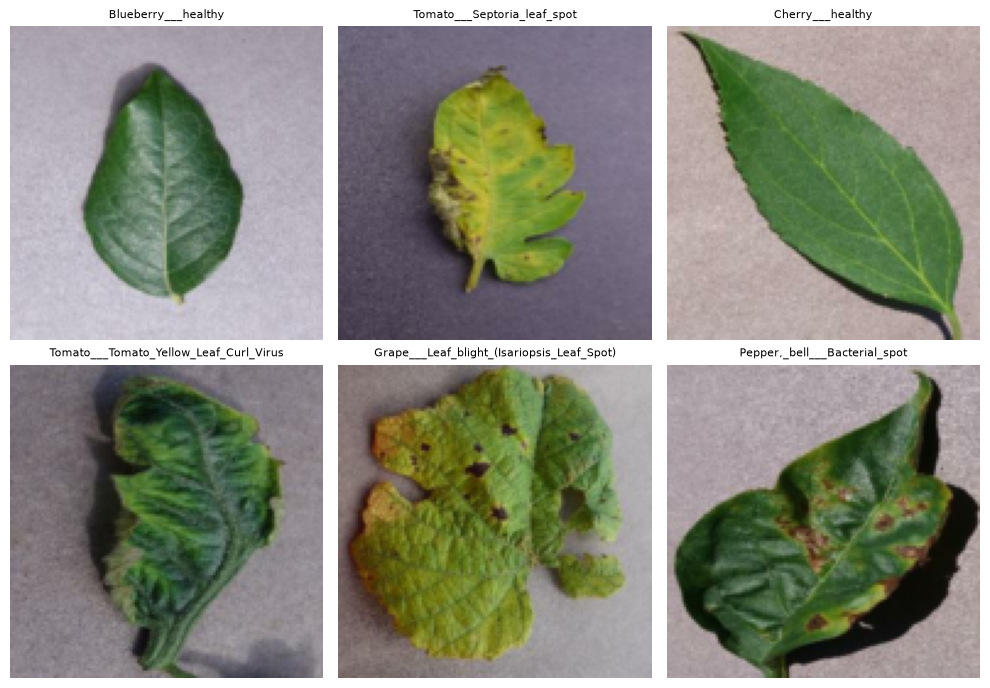

In [ ]:
# Step 8: Visualize images from a training batch

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
axes = axes.flatten()

for index, ax in enumerate(axes):
    ax.imshow(
        np.clip(images[index].numpy() / 255.0, 0, 1)
    )

    label_index = int(labels[index].numpy())
    ax.set_title(CLASS_NAMES[label_index], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Step 9: Define a custom CNN

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Normalize image pixels from [0, 255] to [0, 1]
    layers.Rescaling(1.0 / 255),

    # Convolution block 1
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    # Convolution block 2
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    # Convolution block 3
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 39)             │         5,031 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,791 (448.40 KB)

 Trainable params: 114,791 (448.40 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Step 10: Configure model training

baseline_path = MODELS_DIR / "plant_disease_cnn_baseline.keras"

callbacks = [
    ModelCheckpoint(
        filepath=str(baseline_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [ ]:
# Step 11: Train the CNN baseline

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10


c:\Users\Hey_Nerd\Desktop\plant-disease-classifier\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1213/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.3357 - loss: 2.3976
Epoch 1: val_loss improved from None to 1.52181, saving model to C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\models\plant_disease_cnn_baseline.keras

Epoch 1: finished saving model to C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\models\plant_disease_cnn_baseline.keras
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 166s 136ms/step - accuracy: 0.3357 - loss: 2.3976 - val_accuracy: 0.5535 - val_loss: 1.5218 - learning_rate: 0.0010
Epoch 2/10
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5696 - loss: 1.4393
Epoch 2: val_loss improved from 1.52181 to 1.01191, saving model to C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\models\plant_disease_cnn_baseline.keras

Epoch 2: finished saving model to C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\models\plant_disease_cnn_baseline.keras
1213/1213 ━━━━━━━━━━━━━━━━━━━━ 164s 136ms/step - accuracy: 0.5696 - loss: 1.4393 - val_accuracy: 0.6922 - val_loss: 1

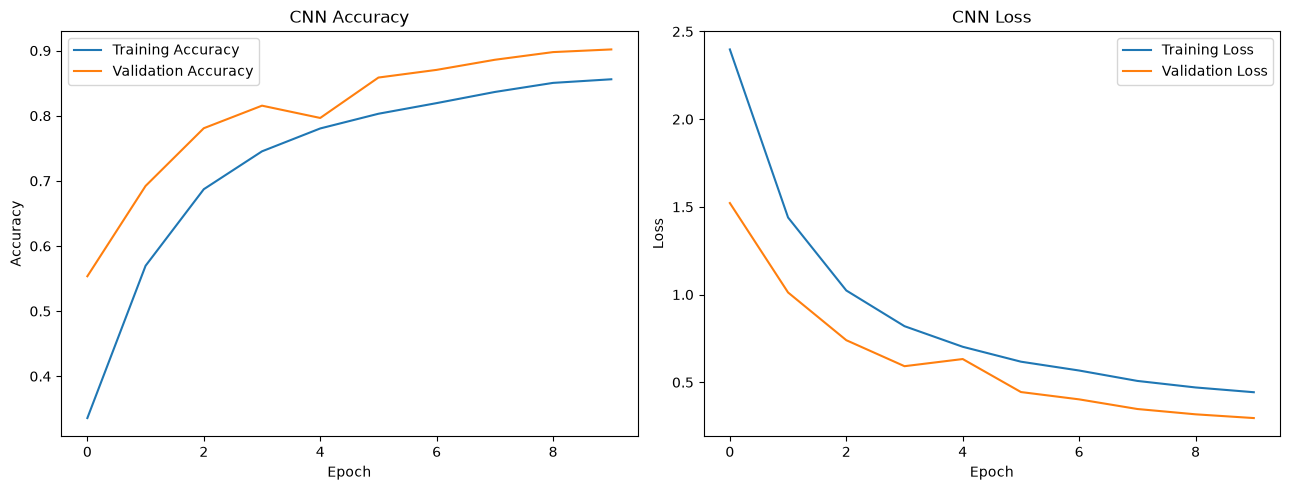

In [ ]:
# Step 12: Plot training and validation curves

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    history.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "cnn_baseline_training_history.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 13. Validation Performance and Error Analysis

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Use the model after training and best-weight restoration.
# val_ds is not shuffled, so predictions align with val_df.
y_true_val = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob_val = model.predict(val_ds, verbose=1)

y_pred_val = np.argmax(y_prob_val, axis=1)

print("Validation samples:", len(y_true_val))
print("Predictions:", len(y_pred_val))
print(
    f"Validation accuracy: "
    f"{accuracy_score(y_true_val, y_pred_val):.4f}"
)

assert len(y_true_val) == len(val_df)
assert len(y_pred_val) == len(val_df)

260/260 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step
Validation samples: 8314
Predictions: 8314
Validation accuracy: 0.9019


In [ ]:
# Classification report for all 39 classes

report = classification_report(
    y_true_val,
    y_pred_val,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(
    report_df.round(4)
)

# Save for the project report
report_path = REPORTS_DIR / "cnn_baseline_validation_report.csv"

report_df.to_csv(report_path)

print("Validation report saved to:", report_path)

print("\nMacro-average metrics:")
display(
    report_df.loc[
        ["macro avg", "weighted avg"],
        ["precision", "recall", "f1-score"]
    ].round(4)
)

,precision,recall,f1-score,support
Apple___Apple_scab,0.8901,0.8526,0.8710,95.0000
Apple___Black_rot,0.8400,0.9032,0.8705,93.0000
Apple___Cedar_apple_rust,0.7959,0.9512,0.8667,41.0000
Apple___healthy,0.9042,0.8821,0.8930,246.0000
Background_without_leaves,0.9701,0.9474,0.9586,171.0000
Blueberry___healthy,0.8947,0.9822,0.9364,225.0000
Cherry___Powdery_mildew,0.9384,0.8671,0.9013,158.0000
Cherry___healthy,0.9609,0.9609,0.9609,128.0000
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.9167,0.2857,0.4356,77.0000
Corn___Common_rust,0.9372,1.0000,0.9676,179.0000


Validation report saved to: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\reports\cnn_baseline_validation_report.csv

Macro-average metrics:


,precision,recall,f1-score
macro avg,0.8866,0.8745,0.8714
weighted avg,0.9097,0.9019,0.9010


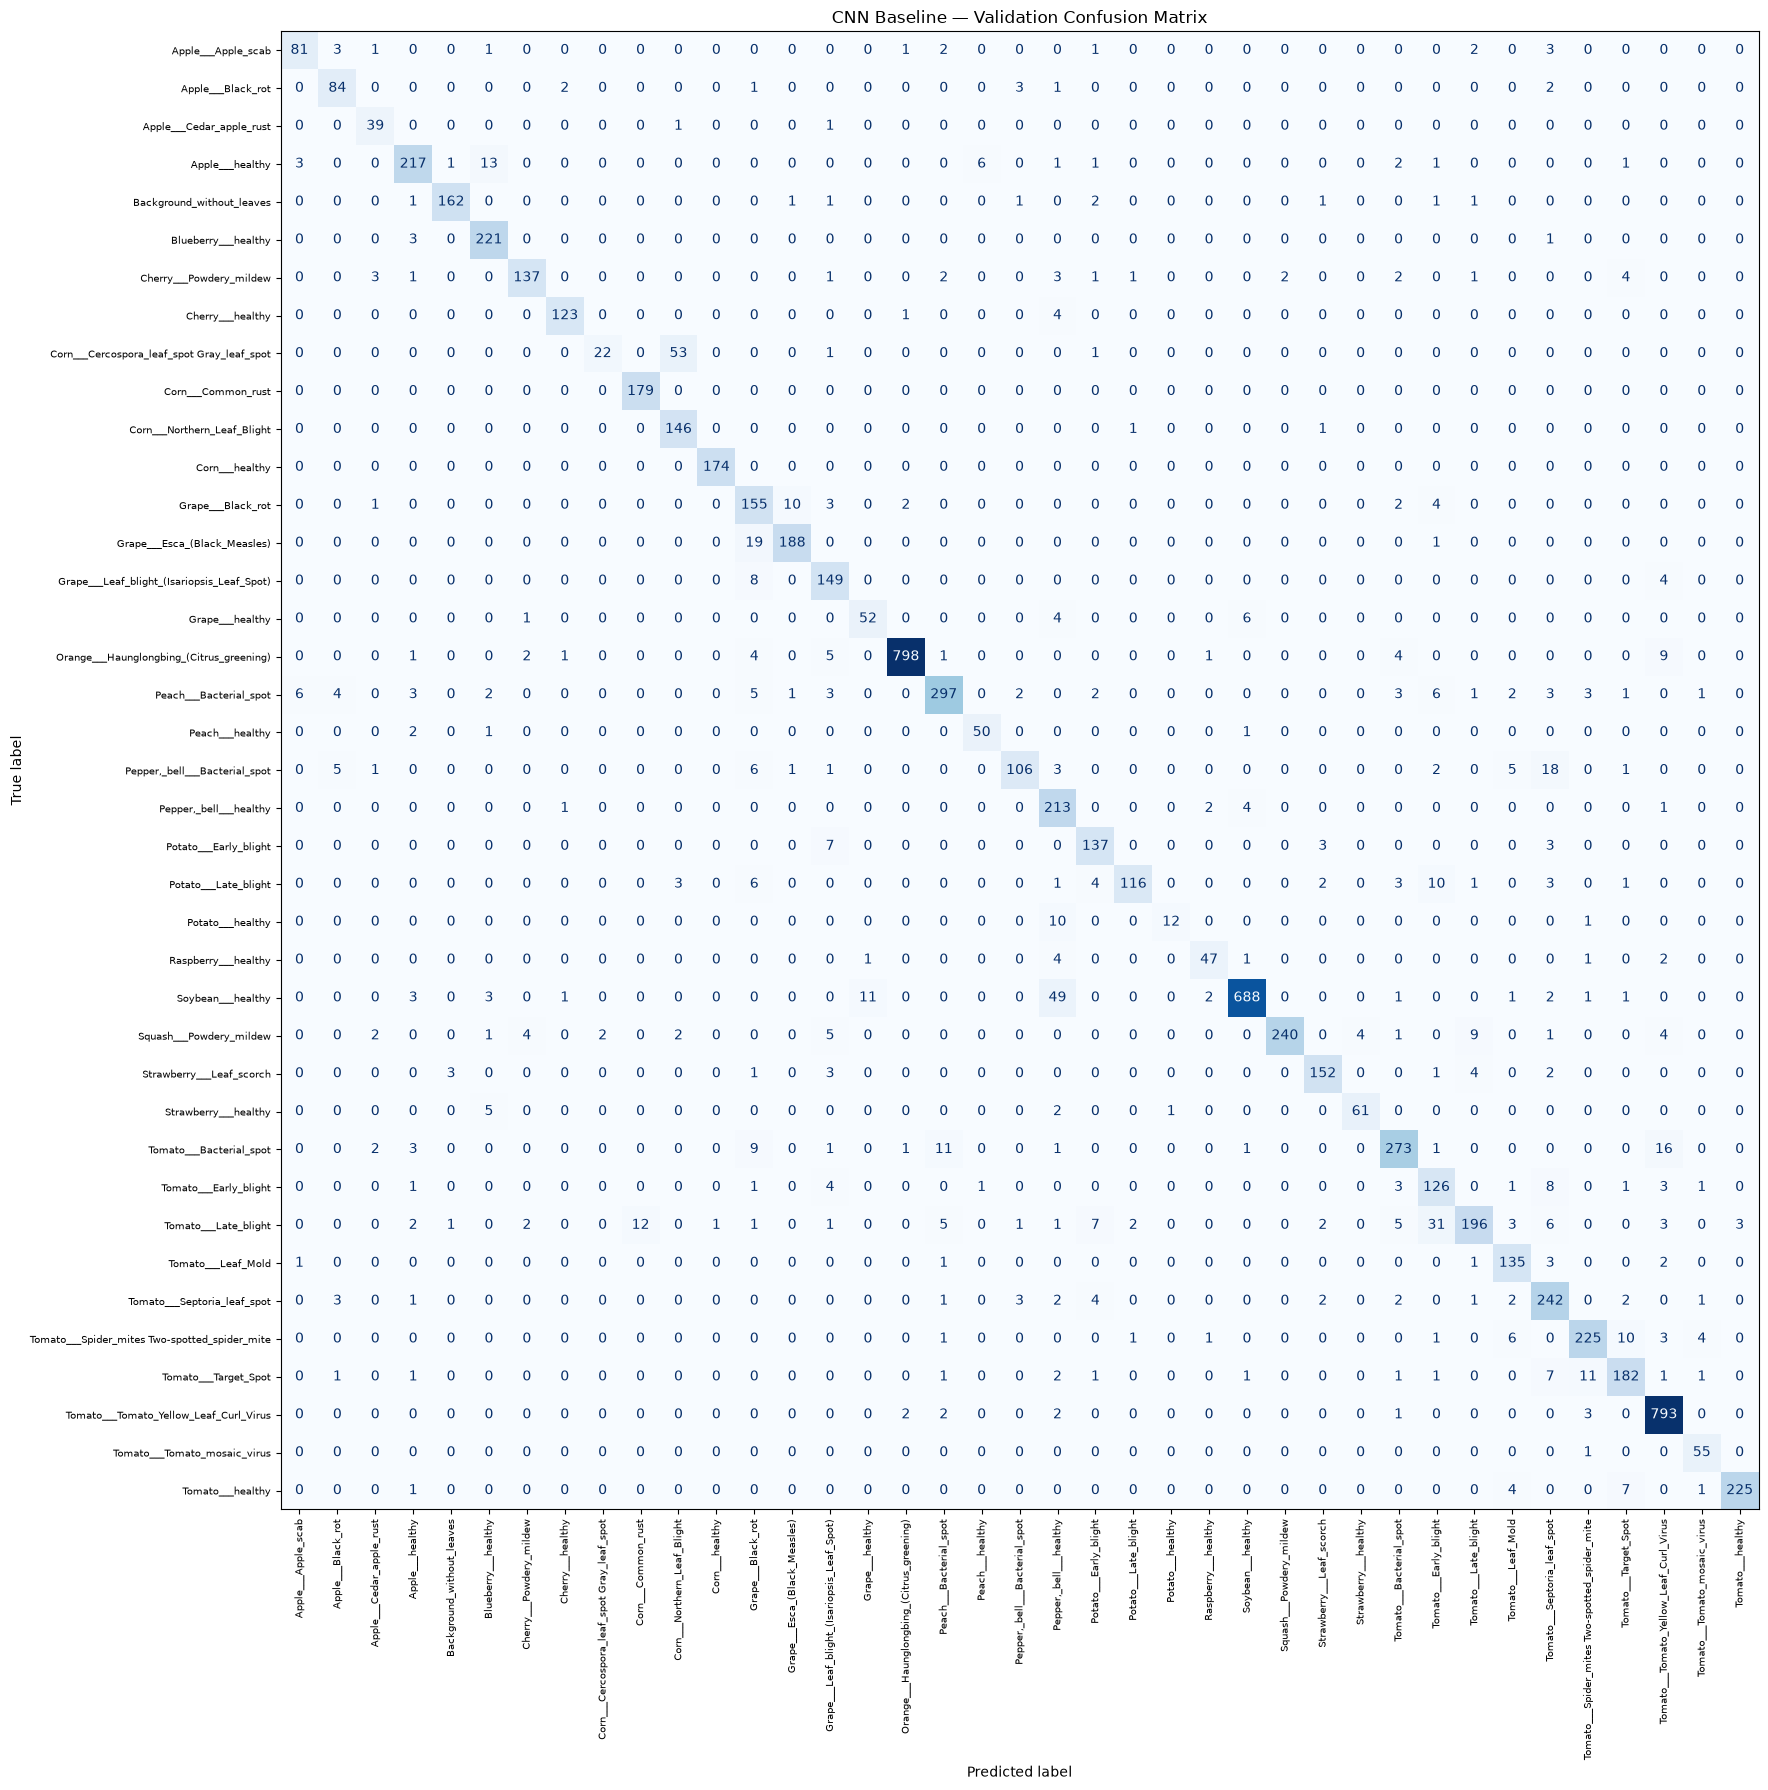

Confusion matrix saved to: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\reports\cnn_baseline_validation_confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true_val,
    y_pred_val,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(20, 18))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display_cm.plot(
    ax=ax,
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_title("CNN Baseline — Validation Confusion Matrix")
ax.tick_params(axis="both", labelsize=7)

plt.tight_layout()

cm_path = REPORTS_DIR / "cnn_baseline_validation_confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved to:", cm_path)

## 14. Identify the Most Difficult Classes

In [ ]:
# Cell 14.1: Rank classes by F1-score

metric_columns = [
    "precision",
    "recall",
    "f1-score",
    "support"
]

per_class_metrics = (
    report_df.loc[CLASS_NAMES, metric_columns]
    .copy()
)

per_class_metrics["support"] = (
    per_class_metrics["support"].astype(int)
)

hardest_classes = per_class_metrics.sort_values(
    "f1-score",
    ascending=True
)

print("10 classes with the lowest validation F1-score:")

display(hardest_classes.head(10).round(4))

10 classes with the lowest validation F1-score:


,precision,recall,f1-score,support
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.9167,0.2857,0.4356,77
Potato___healthy,0.9231,0.5217,0.6667,23
Tomato___Early_blight,0.6774,0.8400,0.7500,150
Tomato___Late_blight,0.9032,0.6877,0.7809,285
Grape___Black_rot,0.7176,0.8757,0.7888,177
"Pepper,_bell___Bacterial_spot",0.9138,0.7114,0.8000,149
"Pepper,_bell___healthy",0.7030,0.9638,0.8130,221
Grape___healthy,0.8125,0.8254,0.8189,63
Corn___Northern_Leaf_Blight,0.7122,0.9865,0.8272,148
Tomato___Septoria_leaf_spot,0.7961,0.9098,0.8491,266


In [ ]:
# Cell 14.2: Find the most common incorrect class predictions

import numpy as np
import pandas as pd

cm_without_diagonal = cm.copy()
np.fill_diagonal(cm_without_diagonal, 0)

confusion_records = []

for true_index, predicted_index in np.argwhere(
    cm_without_diagonal > 0
):
    actual_count = int(cm[true_index].sum())
    error_count = int(cm[true_index, predicted_index])

    confusion_records.append({
        "actual_class": CLASS_NAMES[true_index],
        "predicted_class": CLASS_NAMES[predicted_index],
        "incorrect_predictions": error_count,
        "percentage_of_actual_class": round(
            error_count / actual_count * 100, 2
        ) if actual_count else 0
    })

confusion_pairs = (
    pd.DataFrame(confusion_records)
    .sort_values("incorrect_predictions", ascending=False)
    .reset_index(drop=True)
)

print("10 most frequent incorrect predictions:")

display(confusion_pairs.head(10))

10 most frequent incorrect predictions:


,actual_class,predicted_class,incorrect_predictions,percentage_of_actual_class
0,Corn___Cercospora_leaf_spot Gray_leaf_spot,Corn___Northern_Leaf_Blight,53,68.83
1,Soybean___healthy,"Pepper,_bell___healthy",49,6.42
2,Tomato___Late_blight,Tomato___Early_blight,31,10.88
3,Grape___Esca_(Black_Measles),Grape___Black_rot,19,9.13
4,"Pepper,_bell___Bacterial_spot",Tomato___Septoria_leaf_spot,18,12.08
5,Tomato___Bacterial_spot,Tomato___Tomato_Yellow_Leaf_Curl_Virus,16,5.02
6,Apple___healthy,Blueberry___healthy,13,5.28
7,Tomato___Late_blight,Corn___Common_rust,12,4.21
8,Tomato___Bacterial_spot,Peach___Bacterial_spot,11,3.45
9,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,11,5.21


In [ ]:
# Cell 14.3: Export baseline evaluation artifacts

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

hardest_classes.to_csv(
    REPORTS_DIR / "cnn_baseline_hardest_classes.csv"
)

confusion_pairs.to_csv(
    REPORTS_DIR / "cnn_baseline_common_confusions.csv",
    index=False
)

print("Evaluation reports saved.")

Evaluation reports saved.


In [ ]:
import pandas as pd

REPORTS_DIR = PROJECT_ROOT / "reports"

# Display the 10 classes with the lowest F1-scores
hardest_path = (
    REPORTS_DIR / "cnn_baseline_hardest_classes.csv"
)

hardest_classes = pd.read_csv(
    hardest_path,
    index_col=0
)

print("10 hardest classes:")
display(hardest_classes.head(10).round(4))


# Display the most frequent misclassifications
confusions_path = (
    REPORTS_DIR / "cnn_baseline_common_confusions.csv"
)

common_confusions = pd.read_csv(confusions_path)

print("10 most frequent classification errors:")
display(common_confusions.head(10))

10 hardest classes:


,precision,recall,f1-score,support
Corn___Cercospora_leaf_spot Gray_leaf_spot,0.9167,0.2857,0.4356,77
Potato___healthy,0.9231,0.5217,0.6667,23
Tomato___Early_blight,0.6774,0.8400,0.7500,150
Tomato___Late_blight,0.9032,0.6877,0.7809,285
Grape___Black_rot,0.7176,0.8757,0.7888,177
"Pepper,_bell___Bacterial_spot",0.9138,0.7114,0.8000,149
"Pepper,_bell___healthy",0.7030,0.9638,0.8130,221
Grape___healthy,0.8125,0.8254,0.8189,63
Corn___Northern_Leaf_Blight,0.7122,0.9865,0.8272,148
Tomato___Septoria_leaf_spot,0.7961,0.9098,0.8491,266


10 most frequent classification errors:


,actual_class,predicted_class,incorrect_predictions,percentage_of_actual_class
0,Corn___Cercospora_leaf_spot Gray_leaf_spot,Corn___Northern_Leaf_Blight,53,68.83
1,Soybean___healthy,"Pepper,_bell___healthy",49,6.42
2,Tomato___Late_blight,Tomato___Early_blight,31,10.88
3,Grape___Esca_(Black_Measles),Grape___Black_rot,19,9.13
4,"Pepper,_bell___Bacterial_spot",Tomato___Septoria_leaf_spot,18,12.08
5,Tomato___Bacterial_spot,Tomato___Tomato_Yellow_Leaf_Curl_Virus,16,5.02
6,Apple___healthy,Blueberry___healthy,13,5.28
7,Tomato___Late_blight,Corn___Common_rust,12,4.21
8,Tomato___Bacterial_spot,Peach___Bacterial_spot,11,3.45
9,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,11,5.21
